# 01 · Logistic Regression, Naive Bayes, KNN & SVM

**Phase 5 — Section 5.2 Classification | Notebook 1 of 2**

### Why this matters
Regression (Section 5.1) predicts a number. Classification predicts a **category** — and
it's the more common task in practice (fraud/not-fraud, disease/no-disease, churn/stay).
This notebook covers four genuinely different strategies for drawing a decision boundary
between classes, on a real medical dataset.

### The real dataset: Pima Indians Diabetes

768 real patient records — glucose, blood pressure, BMI, age, and other diagnostic
measurements, with a binary outcome: diabetes onset within 5 years. Loaded directly from
GitHub (a classic UCI dataset, no header row in the raw file, so we supply column names).

```
https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv"
columns = ["pregnancies", "glucose", "blood_pressure", "skin_thickness", "insulin",
           "bmi", "diabetes_pedigree", "age", "outcome"]
df = pd.read_csv(url, names=columns)
print(df.shape)
df.head()

(768, 9)


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 0. A quick, honest data-quality check (Section 2.2 skills, applied)

In [2]:
# A well-known quirk of this real dataset: 0 is used as a MISSING VALUE placeholder for
# several columns where a true biological zero is impossible (you cannot have 0 glucose or 0 BMI)
zero_as_missing_cols = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
for col in zero_as_missing_cols:
    n_zero = (df[col] == 0).sum()
    print(f"{col:<16} has {n_zero:>3} rows recorded as exactly 0 ({n_zero/len(df):.1%})")

glucose          has   5 rows recorded as exactly 0 (0.7%)
blood_pressure   has  35 rows recorded as exactly 0 (4.6%)
skin_thickness   has 227 rows recorded as exactly 0 (29.6%)
insulin          has 374 rows recorded as exactly 0 (48.7%)
bmi              has  11 rows recorded as exactly 0 (1.4%)


> ⚠️ **This is real-world messiness, exactly like Section 2.2 warned you about.** These
> zeros aren't measurements — they're missing data encoded badly by whoever prepared this
> file decades ago. We'll treat them as missing and impute, rather than trusting them as
> real biological values.

In [3]:
df_clean = df.copy()
df_clean[zero_as_missing_cols] = df_clean[zero_as_missing_cols].replace(0, np.nan)
print("missing values after marking zeros as NaN:\n", df_clean.isna().sum())

missing values after marking zeros as NaN:
 pregnancies            0
glucose                5
blood_pressure        35
skin_thickness       227
insulin              374
bmi                   11
diabetes_pedigree      0
age                    0
outcome                0
dtype: int64


## 1. Preparing the data

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

X = df_clean.drop(columns="outcome")
y = df_clean["outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print(f"train: {len(X_train)}, test: {len(X_test)}, positive rate: {y.mean():.1%}")

preprocessing = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

train: 576, test: 192, positive rate: 34.9%


## 2. Logistic Regression — probability via the sigmoid (Module 1.6 payoff)

Despite the name, Logistic Regression is a **classifier**: it fits a linear combination of
features, then squashes it through the sigmoid function into a 0-1 probability, trained by
minimizing cross-entropy loss — exactly the loss you derived from first principles in
Module 1.6.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

logreg = Pipeline([("prep", preprocessing), ("model", LogisticRegression())])
logreg.fit(X_train, y_train)
logreg_proba = logreg.predict_proba(X_test)[:, 1]
logreg_pred = logreg.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, logreg_pred):.4f}")
print(f"ROC AUC:  {roc_auc_score(y_test, logreg_proba):.4f}")
print(classification_report(y_test, logreg_pred))

Accuracy: 0.7240
ROC AUC:  0.8239
              precision    recall  f1-score   support

           0       0.76      0.84      0.80       125
           1       0.63      0.51      0.56        67

    accuracy                           0.72       192
   macro avg       0.70      0.67      0.68       192
weighted avg       0.72      0.72      0.72       192



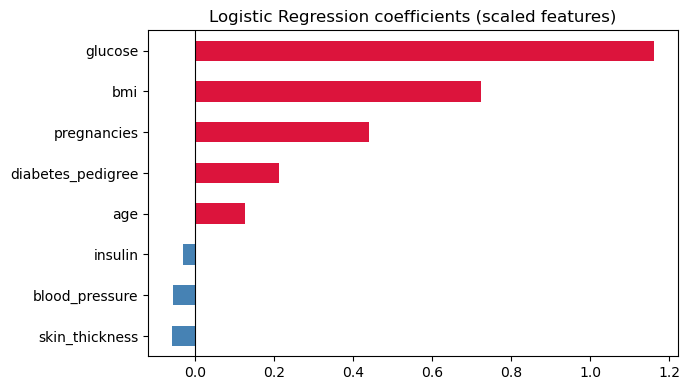

In [6]:
coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
coefs.plot(kind="barh", ax=ax, color=np.where(coefs > 0, "crimson", "steelblue"))
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Logistic Regression coefficients (scaled features)")
plt.tight_layout(); plt.show()

## 3. Naive Bayes — a direct application of Module 1.3's Bayes' Theorem

Naive Bayes applies Bayes' theorem directly: for a new patient, it computes
$P(\text{diabetes} \mid \text{features})$ by combining each feature's individual
likelihood, under the ("naive") assumption that features are conditionally independent
given the class. It's fast, needs little data, and is a genuinely strong baseline.

In [7]:
from sklearn.naive_bayes import GaussianNB

# GaussianNB assumes each feature is normally distributed within each class (Module 1.3)
nb = Pipeline([("prep", preprocessing), ("model", GaussianNB())])
nb.fit(X_train, y_train)
nb_proba = nb.predict_proba(X_test)[:, 1]
nb_pred = nb.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, nb_pred):.4f}")
print(f"ROC AUC:  {roc_auc_score(y_test, nb_proba):.4f}")

Accuracy: 0.7240
ROC AUC:  0.7801


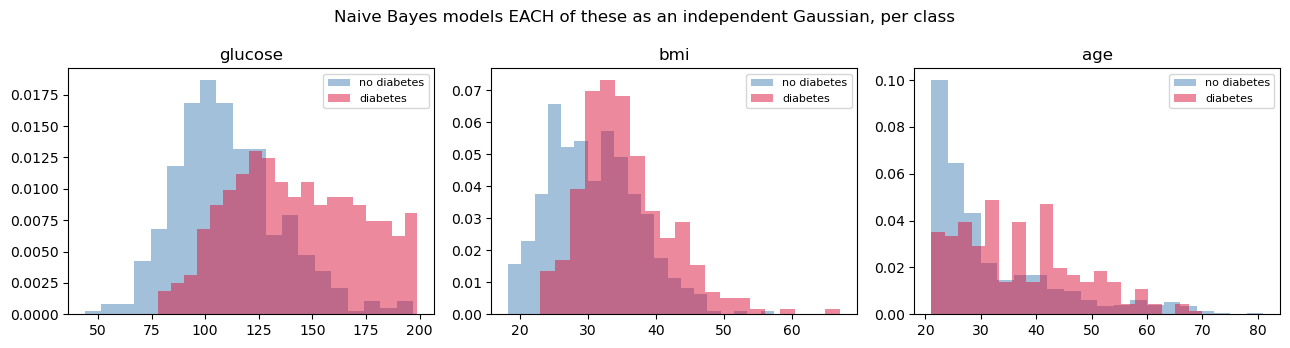

In [8]:
# Visualizing the "naive" per-feature Gaussian assumption directly
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, feature in zip(axes, ["glucose", "bmi", "age"]):
    for outcome_val, color, label in [(0, "steelblue", "no diabetes"), (1, "crimson", "diabetes")]:
        subset = df_clean.loc[df_clean["outcome"] == outcome_val, feature].dropna()
        ax.hist(subset, bins=20, alpha=0.5, density=True, color=color, label=label)
    ax.set_title(feature); ax.legend(fontsize=8)
plt.suptitle("Naive Bayes models EACH of these as an independent Gaussian, per class")
plt.tight_layout(); plt.show()

> 💡 **Where "naive" shows up:** Naive Bayes ignores correlations BETWEEN features (e.g.
> BMI and glucose may genuinely be related) — a simplifying assumption that's rarely
> perfectly true, yet the model often still performs well in practice. This is a
> recurring theme in ML: a "wrong" simplifying assumption can still produce a genuinely
> useful model.

## 4. K-Nearest Neighbors — Module 1.1's distances, used directly for classification

KNN classifies a new point by looking at its `k` nearest neighbors (Module 1.1's distance
metrics) in the training data and taking a majority vote. No training phase in the usual
sense — all the "learning" happens at prediction time.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

# choosing k via cross-validation (Phase 4 skills) rather than guessing
k_values = range(1, 30, 2)
cv_scores = []
for k in k_values:
    knn = Pipeline([("prep", preprocessing), ("model", KNeighborsClassifier(n_neighbors=k))])
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring="roc_auc")
    cv_scores.append(scores.mean())

best_k = list(k_values)[np.argmax(cv_scores)]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(list(k_values), cv_scores, marker="o", color="steelblue")
ax.axvline(best_k, color="crimson", ls="--", label=f"best k = {best_k}")
ax.set_xlabel("k (number of neighbors)"); ax.set_ylabel("cross-validated ROC AUC")
ax.legend()
ax.set_title("Choosing k via cross-validation, not guessing")
plt.tight_layout(); plt.show()

In [ ]:
knn = Pipeline([("prep", preprocessing), ("model", KNeighborsClassifier(n_neighbors=best_k))])
knn.fit(X_train, y_train)
knn_proba = knn.predict_proba(X_test)[:, 1]
knn_pred = knn.predict(X_test)
print(f"KNN (k={best_k}) -- Accuracy: {accuracy_score(y_test, knn_pred):.4f}, ROC AUC: {roc_auc_score(y_test, knn_proba):.4f}")

> ⚠️ **Recall Section 4.1's curse of dimensionality.** KNN's "nearest neighbor" notion
> degrades as feature count grows — with only 8 features here it's fine, but this is
> exactly why KNN is rarely the first choice on very high-dimensional data without
> dimensionality reduction (Module 1.1's PCA) first.

## 5. Support Vector Machines — maximizing the margin

SVM finds the decision boundary that maximizes the **margin** — the distance to the
nearest points of each class ("support vectors"). With a non-linear **kernel** (like RBF),
it can separate classes that aren't linearly separable at all, by implicitly projecting
into a higher-dimensional space.

In [ ]:
from sklearn.svm import SVC

svm_linear = Pipeline([("prep", preprocessing), ("model", SVC(kernel="linear", probability=True, random_state=42))])
svm_rbf = Pipeline([("prep", preprocessing), ("model", SVC(kernel="rbf", probability=True, random_state=42))])

for name, model in [("SVM (linear kernel)", svm_linear), ("SVM (RBF kernel)", svm_rbf)]:
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    print(f"{name:<20} Accuracy: {accuracy_score(y_test, pred):.4f}, ROC AUC: {roc_auc_score(y_test, proba):.4f}")

In [ ]:
# Visualizing the kernel trick's effect using just 2 features, for a 2D decision boundary picture
from matplotlib.colors import ListedColormap

X_2d = df_clean[["glucose", "bmi"]].fillna(df_clean[["glucose", "bmi"]].median())
y_2d = df_clean["outcome"]
X_2d_scaled = StandardScaler().fit_transform(X_2d)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, kernel in zip(axes, ["linear", "rbf"]):
    clf = SVC(kernel=kernel).fit(X_2d_scaled, y_2d)
    xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(["steelblue", "crimson"]))
    ax.scatter(X_2d_scaled[:, 0], X_2d_scaled[:, 1], c=y_2d, cmap=ListedColormap(["steelblue", "crimson"]),
               edgecolor="k", s=15, alpha=0.7)
    ax.set_xlabel("glucose (scaled)"); ax.set_ylabel("bmi (scaled)")
    ax.set_title(f"SVM decision boundary -- {kernel} kernel")
plt.tight_layout(); plt.show()

> 💡 **The RBF kernel's boundary curves to fit the data**, while the linear kernel is
> forced to be a straight line — direct, visual proof of what "the kernel trick lets SVM
> separate non-linear patterns" actually means.

## 6. Comparing all four, honestly

In [ ]:
results = pd.DataFrame({
    "model": ["Logistic Regression", "Naive Bayes", f"KNN (k={best_k})", "SVM (linear)", "SVM (RBF)"],
    "accuracy": [
        accuracy_score(y_test, logreg_pred), accuracy_score(y_test, nb_pred), accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_linear.predict(X_test)), accuracy_score(y_test, svm_rbf.predict(X_test)),
    ],
    "roc_auc": [
        roc_auc_score(y_test, logreg_proba), roc_auc_score(y_test, nb_proba), roc_auc_score(y_test, knn_proba),
        roc_auc_score(y_test, svm_linear.predict_proba(X_test)[:, 1]), roc_auc_score(y_test, svm_rbf.predict_proba(X_test)[:, 1]),
    ],
}).set_index("model").sort_values("roc_auc", ascending=False)
results.round(4)

## 🧪 Practice Exercises

**1.** Try `GaussianNB` WITHOUT marking zeros as missing (use the raw `df` instead of
`df_clean`). Does ROC AUC change much? What does that tell you about how much the
zero-as-missing data quality issue actually mattered here?

**2.** Tune the SVM's `C` parameter (try `C=0.1` and `C=10` with the RBF kernel) — what
happens to the decision boundary's smoothness in the 2D visualization?

**3.** Which single model from section 6 would you recommend deploying, and why — is ROC
AUC alone enough to decide, or would you want to check calibration (Section 4.3) too,
given this is a medical screening context?

In [ ]:
# --- Exercise 1 ---
X_raw = df.drop(columns="outcome")
y_raw = df["outcome"]
X_train_raw, X_test_raw, y_train_raw, y_test_raw = train_test_split(X_raw, y_raw, test_size=0.25, random_state=42, stratify=y_raw)

nb_raw = Pipeline([("prep", preprocessing), ("model", GaussianNB())]).fit(X_train_raw, y_train_raw)
raw_auc = roc_auc_score(y_test_raw, nb_raw.predict_proba(X_test_raw)[:, 1])
print(f"ROC AUC without cleaning the zeros: {raw_auc:.4f}")
print(f"ROC AUC WITH cleaning (from section 3): {roc_auc_score(y_test, nb_proba):.4f}")

In [ ]:
# --- Exercise 2 ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, C in zip(axes, [0.1, 10]):
    clf = SVC(kernel="rbf", C=C).fit(X_2d_scaled, y_2d)
    xx, yy = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200))
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap=ListedColormap(["steelblue", "crimson"]))
    ax.scatter(X_2d_scaled[:, 0], X_2d_scaled[:, 1], c=y_2d, cmap=ListedColormap(["steelblue", "crimson"]), edgecolor="k", s=15, alpha=0.7)
    ax.set_title(f"RBF kernel, C={C}")
plt.tight_layout(); plt.show()
print("Small C -> smoother, simpler boundary (more regularization).")
print("Large C -> more complex, tightly-fit boundary (less regularization, risk of overfitting).")

**Exercise 3 answer:** ROC AUC alone is not enough for a medical screening context. Given
Section 4.3's calibration lesson, you'd want to check whether the model's predicted
probabilities are trustworthy at the specific threshold used for clinical decisions, and
you'd likely prioritize **recall** (catching true diabetes cases) over raw accuracy or AUC,
since a missed case is far more costly than a false alarm that leads to a confirmatory
test — the same reasoning from Section 4.3's precision/recall cost discussion.

---
### ✅ Checkpoint
You should now be able to:
- Fit and interpret Logistic Regression's coefficients for a classification problem
- Explain the "naive" independence assumption in Naive Bayes and why it can still work well
- Choose `k` for KNN via cross-validation rather than guessing
- Explain what the kernel trick does for SVM, with a visual decision boundary as evidence

**Next notebook:** `02_trees_ensembles_and_neural_net_preview.ipynb` — the tree family
(again) plus your first glimpse of a neural network, applied to classification.